# 08 · Generalized linear models: logistic vs Poisson

A GLM = linear predictor + **link** + **distribution**. Logistic uses a binomial family with a logit link (binary outcomes). Poisson uses a log link (counts).

Our data has both kinds of outcome:
- `no_fire` = 1 if the tract has **no** `fire_department` POI (binary). 70% of tracts.
- `fire_n`, `poi_n` = counts of POIs in the tract.

Needs `model_frame.parquet` from notebook 06.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pathlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm, statsmodels.formula.api as smf
from scipy import stats

ROOT = pathlib.Path.cwd().resolve(); ROOT = ROOT.parent if ROOT.name in ("notebooks", "analysis_scripts") else ROOT
OUT = ROOT / "analysis_outputs"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
SEED = 42
rng = np.random.default_rng(SEED)
f = pd.read_parquet(OUT / "model_frame.parquet")      # built in notebook 06
rmse = lambda a, b: float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

7279 train / 2427 test


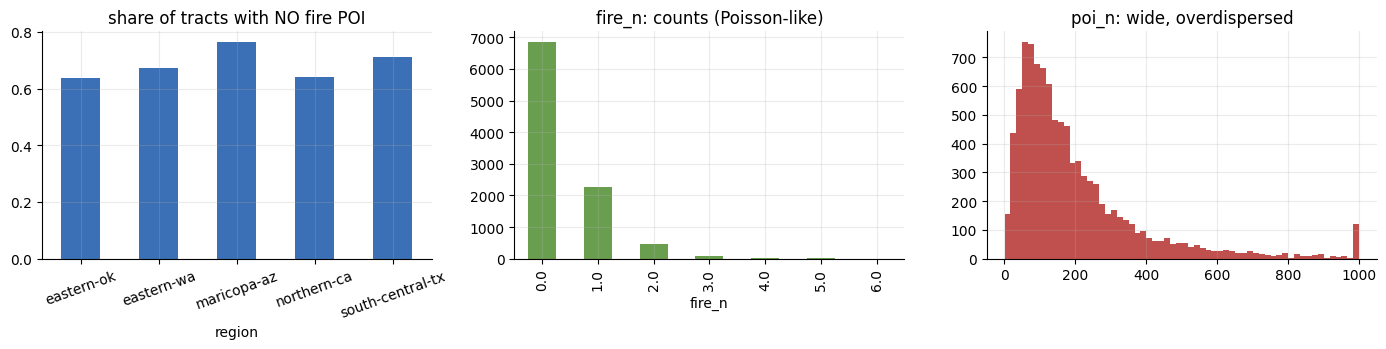

In [2]:
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
s = f.dropna(subset=["log_pop_density", "svi", "log_area_km2"]).reset_index(drop=True).copy()
for c in ["log_pop_density", "svi", "log_area_km2", "log_road_density"]:
    s[c + "_z"] = (s[c] - s[c].mean()) / s[c].std()
tr, te = train_test_split(s, test_size=.25, random_state=SEED, stratify=s.region)
print(len(tr), "train /", len(te), "test")
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
s.groupby("region").no_fire.mean().plot.bar(ax=ax[0], color="#3b6fb6", rot=20); ax[0].set_title("share of tracts with NO fire POI")
s.fire_n.value_counts().sort_index().plot.bar(ax=ax[1], color="#6a9e4f"); ax[1].set_title("fire_n: counts (Poisson-like)")
s.poi_n.clip(upper=1000).hist(bins=60, ax=ax[2], color="#c0504d"); ax[2].set_title("poi_n: wide, overdispersed")
plt.tight_layout(); plt.show()

**Comment:** fire POIs are rare small counts; total POIs have a long right tail. These are exactly the shapes logistic / Poisson / negative-binomial models are built for.

## 1 · Logistic regression: does a tract have *no* fire station POI?

C(region)[T.eastern-wa]          1.25
C(region)[T.maricopa-az]         1.33
C(region)[T.northern-ca]         0.87
C(region)[T.south-central-tx]    1.02
log_area_km2_z                   0.24
log_pop_density_z                0.48
rural                            1.02
tribal                           0.91
svi_z                            0.91
test AUC = 0.697   (null deviance 8835 -> residual 7992)


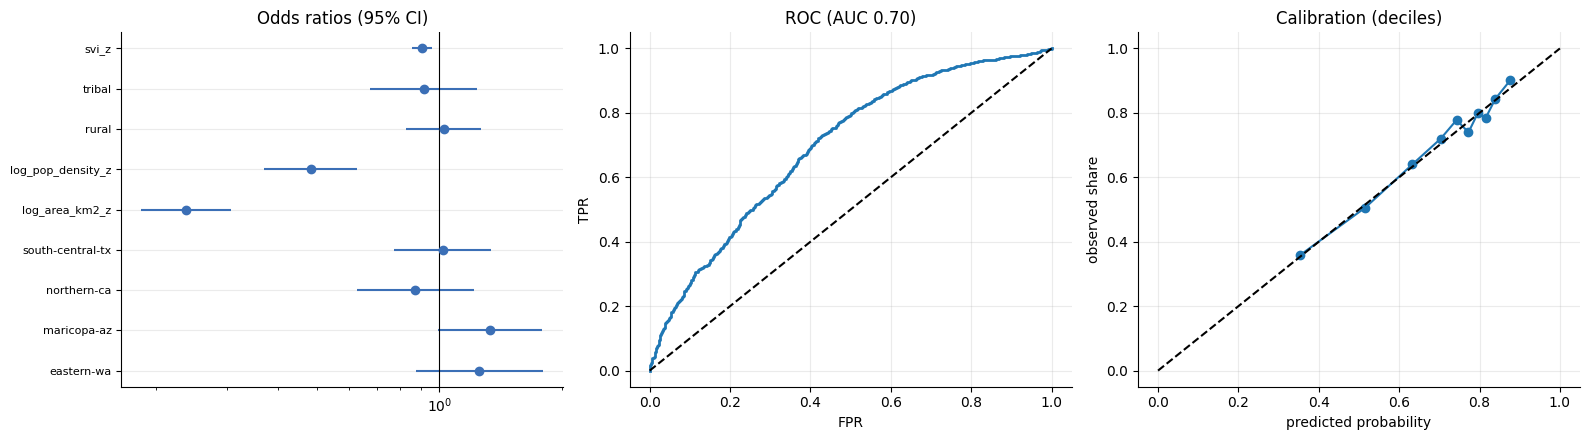

In [3]:
form = "no_fire ~ log_area_km2_z + log_pop_density_z + rural + tribal + svi_z + C(region)"
lg = smf.glm(form, tr, family=sm.families.Binomial()).fit()
orr = np.exp(lg.params.drop("Intercept")); ci = np.exp(lg.conf_int().drop("Intercept"))
p = lg.predict(te); auc = roc_auc_score(te.no_fire, p)
print(orr.round(2).to_string())
print(f"test AUC = {auc:.3f}   (null deviance {lg.null_deviance:.0f} -> residual {lg.deviance:.0f})")
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].errorbar(orr, range(len(orr)), xerr=[orr - ci[0], ci[1] - orr], fmt="o", color="#3b6fb6"); ax[0].axvline(1, color="k", lw=.8); ax[0].set_xscale("log")
ax[0].set_yticks(range(len(orr))); ax[0].set_yticklabels([i.replace("C(region)[T.", "").rstrip("]") for i in orr.index], fontsize=8); ax[0].set_title("Odds ratios (95% CI)")
fpr, tpr, _ = roc_curve(te.no_fire, p); ax[1].plot(fpr, tpr, lw=2); ax[1].plot([0, 1], [0, 1], "k--"); ax[1].set(xlabel="FPR", ylabel="TPR", title=f"ROC (AUC {auc:.2f})")
cal = pd.DataFrame({"p": p, "y": te.no_fire}); cal["bin"] = pd.qcut(cal.p, 10, duplicates="drop"); g = cal.groupby("bin").agg(p=("p", "mean"), y=("y", "mean"))
ax[2].plot(g.p, g.y, "o-"); ax[2].plot([0, 1], [0, 1], "k--"); ax[2].set(xlabel="predicted probability", ylabel="observed share", title="Calibration (deciles)")
plt.tight_layout(); plt.show()

**Comment:** each SD of tract area cuts the odds of having no fire POI to 0.24x (a bigger box simply contains more places), and each SD of population density to 0.48x. Odds ratios above 1 mean *more* likely to have no fire POI. Test AUC is only 0.70, so presence of a fire POI is hard to predict from tract attributes.

## 2 · Poisson regression: how many fire POIs? (with exposure)
A tract's *area* is the natural exposure, so we model the **rate per km2** with `offset = log(area)`.

Poisson dispersion (Pearson chi2 / df) = 1.34   (1 means Poisson variance is fine)
C(region)[T.eastern-wa]          0.70
C(region)[T.maricopa-az]         0.66
C(region)[T.northern-ca]         0.93
C(region)[T.south-central-tx]    0.81
log_pop_density_z                4.56
rural                            1.10
tribal                           0.99
svi_z                            1.07


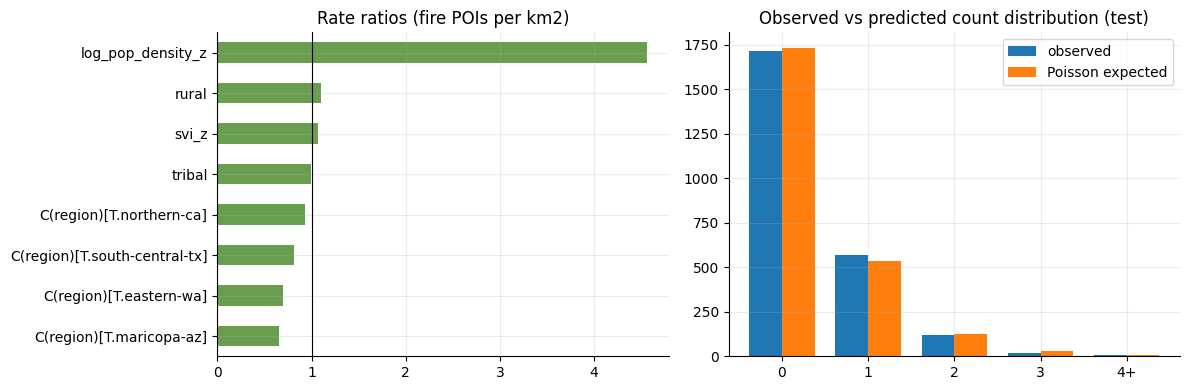

In [4]:
s["area_km2"] = np.exp(s.log_area_km2); tr["area_km2"] = np.exp(tr.log_area_km2); te["area_km2"] = np.exp(te.log_area_km2)
form = "fire_n ~ log_pop_density_z + rural + tribal + svi_z + C(region)"
po = smf.glm(form, tr, family=sm.families.Poisson(), offset=np.log(tr.area_km2)).fit()
disp = po.pearson_chi2 / po.df_resid
print(f"Poisson dispersion (Pearson chi2 / df) = {disp:.2f}   (1 means Poisson variance is fine)")
rr = np.exp(po.params.drop("Intercept")); print(rr.round(2).to_string())
mu = po.predict(te, offset=np.log(te.area_km2))
exp_counts = pd.DataFrame({k: stats.poisson.pmf(k, mu).sum() for k in range(5)}, index=["expected"]).T
obs = te.fire_n.clip(upper=4).value_counts().sort_index()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
rr.sort_values().plot.barh(ax=ax[0], color="#6a9e4f"); ax[0].axvline(1, color="k", lw=.8); ax[0].set_title("Rate ratios (fire POIs per km2)")
w = .38; ks = np.arange(5)
ax[1].bar(ks - w / 2, obs.reindex(ks).fillna(0), w, label="observed"); ax[1].bar(ks + w / 2, exp_counts.expected.values, w, label="Poisson expected")
ax[1].set_xticks(ks); ax[1].set_xticklabels(["0", "1", "2", "3", "4+"]); ax[1].legend(); ax[1].set_title("Observed vs predicted count distribution (test)")
plt.tight_layout(); plt.show()

**Comment:** with the area offset, coefficients are rate ratios per km2: each SD of density multiplies the fire-POI rate by about 4.6 (stations cluster where people live). Dispersion is 1.34, close enough to 1 that plain Poisson is acceptable for fire POIs.

## 3 · Logistic vs Poisson on the *same* event
For rare events the two tell the same story: P(no fire) can be recovered from the Poisson rate as `exp(-mu)`. Compare the two predictions.

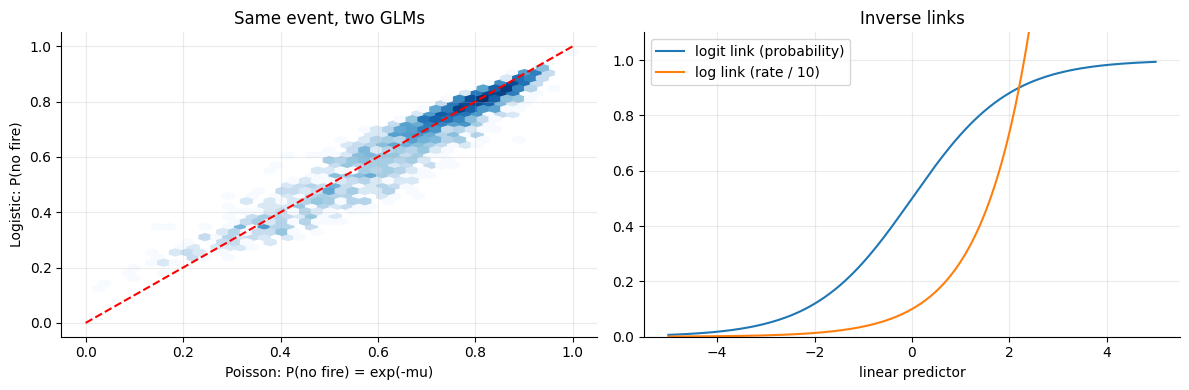

AUC logistic 0.697  |  AUC via Poisson 0.684


In [5]:
p_log = lg.predict(te)
p_poi = np.exp(-mu)                       # P(count = 0) under Poisson
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hexbin(p_poi, p_log, gridsize=40, cmap="Blues", mincnt=1, bins="log"); ax[0].plot([0, 1], [0, 1], "r--")
ax[0].set(xlabel="Poisson: P(no fire) = exp(-mu)", ylabel="Logistic: P(no fire)", title="Same event, two GLMs")
x = np.linspace(-5, 5, 200)
ax[1].plot(x, 1 / (1 + np.exp(-x)), label="logit link (probability)"); ax[1].plot(x, np.exp(x) / 10, label="log link (rate / 10)")
ax[1].set_ylim(0, 1.1); ax[1].legend(); ax[1].set_title("Inverse links"); ax[1].set_xlabel("linear predictor")
plt.tight_layout(); plt.show()
print(f"AUC logistic {roc_auc_score(te.no_fire, p_log):.3f}  |  AUC via Poisson {roc_auc_score(te.no_fire, p_poi):.3f}")

**Comment:** the two models rank tracts similarly (AUC 0.697 vs 0.684). Logistic is bounded in [0,1] by construction; Poisson/log link is multiplicative and needs an exposure. Pick logistic when only presence matters, Poisson when counts or rates matter.

## 4 · Case study: overdispersed counts (total POIs) -> Poisson fails, negative binomial fits
Outcome `poi_n`, exposure = buildings (`offset = log(bldg_n)`), so we model POIs *per building*.

Poisson dispersion = 549.6   |   NB alpha (moment estimate) = 1.07
AIC  Poisson 1,516,409   NegBin 94,834
test MAE  Poisson 144.2  NegBin 203.3   |  RMSE Poisson 227.3  NegBin 286.8


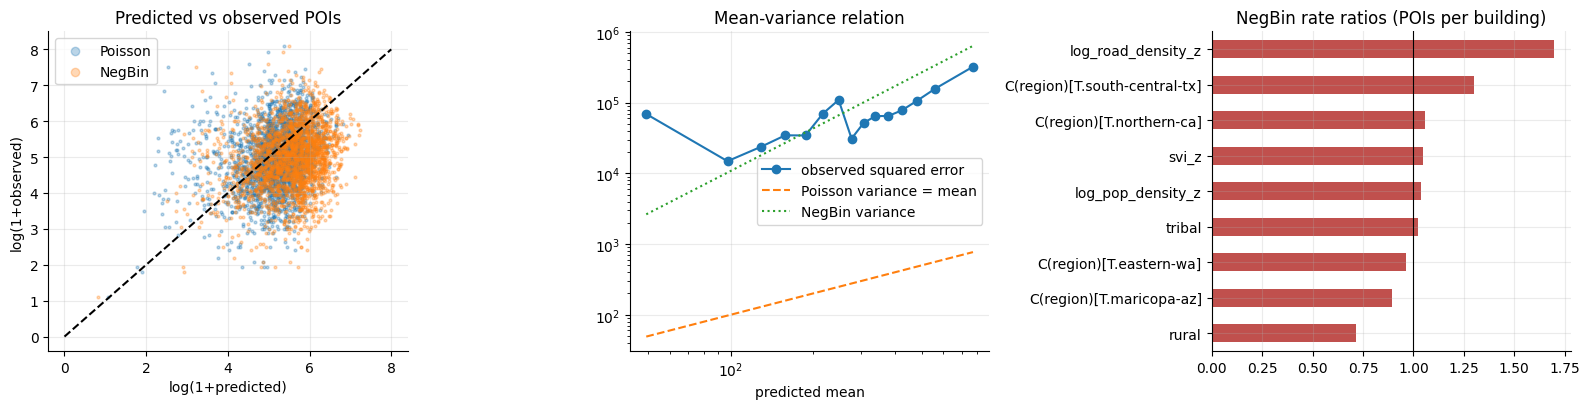

In [6]:
d2 = s[s.bldg_n > 0].copy(); d2["lb"] = np.log(d2.bldg_n)
tr2, te2 = train_test_split(d2, test_size=.25, random_state=SEED, stratify=d2.region)
form = "poi_n ~ log_pop_density_z + rural + tribal + svi_z + log_road_density_z + C(region)"
p2 = smf.glm(form, tr2, family=sm.families.Poisson(), offset=tr2.lb).fit()
m0 = p2.fittedvalues                                    # Cameron-Trivedi moment estimate of the NB2 dispersion alpha
alpha = float(sm.OLS(((tr2.poi_n - m0) ** 2 - m0) / m0, m0).fit().params.iloc[0])
nb = smf.glm(form, tr2, family=sm.families.NegativeBinomial(alpha=alpha), offset=tr2.lb).fit()
print(f"Poisson dispersion = {p2.pearson_chi2 / p2.df_resid:.1f}   |   NB alpha (moment estimate) = {alpha:.2f}")
print(f"AIC  Poisson {p2.aic:,.0f}   NegBin {nb.aic:,.0f}")
mu_p = p2.predict(te2, offset=te2.lb); mu_n = nb.predict(te2, offset=te2.lb)
print(f"test MAE  Poisson {np.mean(abs(te2.poi_n - mu_p)):.1f}  NegBin {np.mean(abs(te2.poi_n - mu_n)):.1f}   |  RMSE Poisson {rmse(te2.poi_n, mu_p):.1f}  NegBin {rmse(te2.poi_n, mu_n):.1f}")
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].scatter(np.log1p(mu_p), np.log1p(te2.poi_n), s=4, alpha=.3, label="Poisson"); ax[0].scatter(np.log1p(mu_n), np.log1p(te2.poi_n), s=4, alpha=.3, label="NegBin")
ax[0].plot([0, 8], [0, 8], "k--"); ax[0].set(xlabel="log(1+predicted)", ylabel="log(1+observed)", title="Predicted vs observed POIs"); ax[0].legend(markerscale=3)
bins = pd.qcut(mu_n, 15, duplicates="drop"); t = pd.DataFrame({"mean": mu_n, "var": (te2.poi_n - mu_n) ** 2, "b": bins}).groupby("b").mean()
ax[1].loglog(t["mean"], t["var"], "o-", label="observed squared error"); ax[1].loglog(t["mean"], t["mean"], "--", label="Poisson variance = mean"); ax[1].loglog(t["mean"], t["mean"] + alpha * t["mean"] ** 2, ":", label="NegBin variance")
ax[1].legend(); ax[1].set_title("Mean-variance relation"); ax[1].set_xlabel("predicted mean")
rr = np.exp(nb.params.drop("Intercept")); rr.sort_values().plot.barh(ax=ax[2], color="#c0504d"); ax[2].axvline(1, color="k", lw=.8); ax[2].set_title("NegBin rate ratios (POIs per building)")
plt.tight_layout(); plt.show()

**Comment:** Poisson assumes variance = mean, but here the dispersion is about 550 and the negative binomial (alpha about 1.07) has an AIC of 95k vs 1.5M, so NB describes the *spread* far better and gives honest standard errors. For raw-count point error, Poisson is actually better (MAE 144 vs 203): NB down-weights the huge-count tracts that dominate absolute error. Use NB for inference and intervals, and judge point predictions by the metric you will be scored on.